In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
df = pd.read_csv("/content/drive/MyDrive/CSV/logistics_sample_data.csv")

In [3]:
print("Shape:", df.shape)
display(df.head())
print(df.dtypes)

Shape: (300, 10)


,order_id,order_date,promised_date,actual_delivery_date,location,product_id,quantity,distance_km,delivery_cost,unit_cost
0,ORD0001,2025-11-24,2025-11-26,2025-11-28,Chennai,T-Shirt,9,54.5,258.89,12831.08
1,ORD0002,2025-01-16,2025-01-17,2025-01-19,Madurai,T-Shirt,8,46.7,255.45,13641.51
2,ORD0003,2025-05-23,2025-05-29,2025-05-31,Trichy,Headphones,1,365.2,953.93,6694.82
3,ORD0004,2025-06-22,2025-06-23,2025-06-24,Coimbatore,Laptop,13,50.5,326.28,16225.97
4,ORD0005,2025-07-13,2025-07-16,2025-07-17,Madurai,Laptop,10,40.1,229.45,7068.58


order_id                 object
order_date               object
promised_date            object
actual_delivery_date     object
location                 object
product_id               object
quantity                  int64
distance_km             float64
delivery_cost           float64
unit_cost               float64
dtype: object


In [4]:
print("Missing values:\\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe())

Missing values:\n order_id                0
order_date              0
promised_date           0
actual_delivery_date    0
location                0
product_id              0
quantity                0
distance_km             0
delivery_cost           0
unit_cost               0
dtype: int64
Duplicate rows: 0


,quantity,distance_km,delivery_cost,unit_cost
count,300.000000,300.000000,300.000000,300.000000
mean,10.940000,236.470667,739.218800,15071.292867
std,5.493968,126.755530,303.070928,8665.794353
min,1.000000,12.000000,131.390000,376.190000
25%,7.000000,120.775000,457.350000,8051.927500
50%,11.000000,244.900000,765.275000,14781.035000
75%,15.250000,339.800000,984.015000,21992.952500
max,20.000000,446.300000,1316.250000,29987.970000


Remove duplicates and validate values

In [7]:
df_clean = df.drop_duplicates().copy()
print("Rows before:", len(df), "Rows after deduplication:", len(df_clean))

Rows before: 300 Rows after deduplication: 300


Handle missing values

In [10]:
# Since there are 0 missing values in the dataset, missing value handling is not required.
# Let's calculate the delivery time by finding the difference between order_date and actual_delivery_date

df_clean['order_date'] = pd.to_datetime(df_clean['order_date'])
df_clean['actual_delivery_date'] = pd.to_datetime(df_clean['actual_delivery_date'])
df_clean['promised_date'] = pd.to_datetime(df_clean['promised_date'])

df_clean['delivery_time_days'] = (df_clean['actual_delivery_date'] - df_clean['order_date']).dt.days

print("Columns in cleaned DataFrame:", df_clean.columns.tolist())
display(df_clean[['order_date', 'actual_delivery_date', 'delivery_time_days']].head())

Columns in cleaned DataFrame: ['order_id', 'order_date', 'promised_date', 'actual_delivery_date', 'location', 'product_id', 'quantity', 'distance_km', 'delivery_cost', 'unit_cost', 'delivery_time_days']


,order_date,actual_delivery_date,delivery_time_days
0,2025-11-24,2025-11-28,4
1,2025-01-16,2025-01-19,3
2,2025-05-23,2025-05-31,8
3,2025-06-22,2025-06-24,2
4,2025-07-13,2025-07-17,4


Flag potential outliers using IQR

In [13]:
for col in ["distance_km", "delivery_time_days", "delivery_cost", "unit_cost"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"{col}: bounds=({lower:.2f}, {upper:.2f}); potential outliers={count}")
# Flag, investigate, and only remove/cap outliers if domain evidence justifies it.

distance_km: bounds=(-207.76, 668.34); potential outliers=0
delivery_time_days: bounds=(0.00, 8.00); potential outliers=0
delivery_cost: bounds=(-332.65, 1774.01); potential outliers=0
unit_cost: bounds=(-12859.61, 42904.49); potential outliers=0


Normalize and standardize

In [15]:
scaled_cols = ["distance_km", "delivery_time_days", "delivery_cost", "unit_cost"]
df_clean[[c+"_MinMax" for c in scaled_cols]] = MinMaxScaler().fit_transform(df_clean[scaled_cols])
df_clean[[c+"_ZScore" for c in scaled_cols]] = StandardScaler().fit_transform(df_clean[scaled_cols])
display(df_clean.head())

,order_id,order_date,promised_date,actual_delivery_date,location,product_id,quantity,distance_km,delivery_cost,unit_cost,delivery_time_days,distance_km_MinMax,delivery_time_days_MinMax,delivery_cost_MinMax,unit_cost_MinMax,distance_km_ZScore,delivery_time_days_ZScore,delivery_cost_ZScore,unit_cost_ZScore
0,ORD0001,2025-11-24,2025-11-26,2025-11-28,Chennai,T-Shirt,9,54.5,258.89,12831.08,4,0.097859,0.428571,0.107608,0.420606,-1.438002,-0.182212,-1.587521,-0.258944
1,ORD0002,2025-01-16,2025-01-17,2025-01-19,Madurai,T-Shirt,8,46.7,255.45,13641.51,3,0.079899,0.285714,0.104704,0.447974,-1.499641,-0.782910,-1.598890,-0.165267
2,ORD0003,2025-05-23,2025-05-29,2025-05-31,Trichy,Headphones,1,365.2,953.93,6694.82,8,0.813263,1.000000,0.694209,0.213382,1.017269,2.220582,0.709636,-0.968228
3,ORD0004,2025-06-22,2025-06-23,2025-06-24,Coimbatore,Laptop,13,50.5,326.28,16225.97,2,0.088648,0.142857,0.164484,0.535253,-1.469612,-1.383609,-1.364792,0.133468
4,ORD0005,2025-07-13,2025-07-16,2025-07-17,Madurai,Laptop,10,40.1,229.45,7068.58,4,0.064702,0.428571,0.082761,0.226004,-1.551796,-0.182212,-1.684822,-0.925026


Verify, visualize, and export

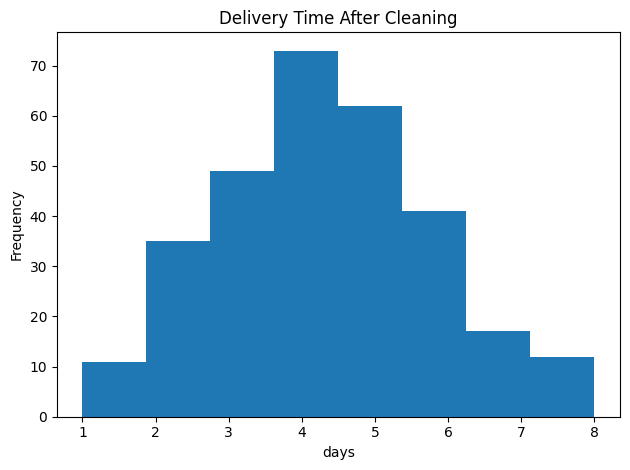

Final shape: (300, 19)
Missing values remaining: 0
Duplicate rows remaining: 0


In [18]:
df_clean["delivery_time_days"].plot(kind="hist", bins=8, title="Delivery Time After Cleaning")
plt.xlabel("days")
plt.tight_layout()
plt.show()
print("Final shape:", df_clean.shape)
print("Missing values remaining:", int(df_clean.isna().sum().sum()))
print("Duplicate rows remaining:", int(df_clean.duplicated().sum()))
out = "logistics_cleaned_preprocessed.csv"
df_clean.to_csv(out, index=False)
